In [160]:
import numpy as np
import pycbc
from pycbc.waveform import get_td_waveform
from gwosc.datasets import event_gps
from gwpy.timeseries import TimeSeries


from pycbc.waveform import get_td_waveform


(50, 50)
Total mass: 720.7936464511091
Number of nodes: 297


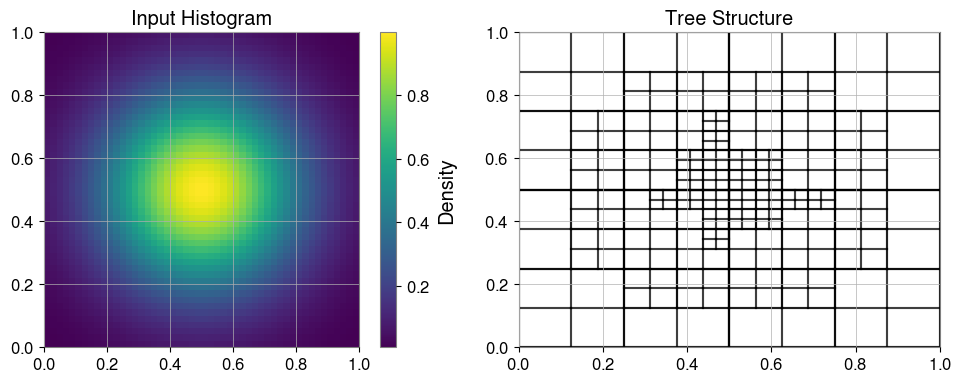

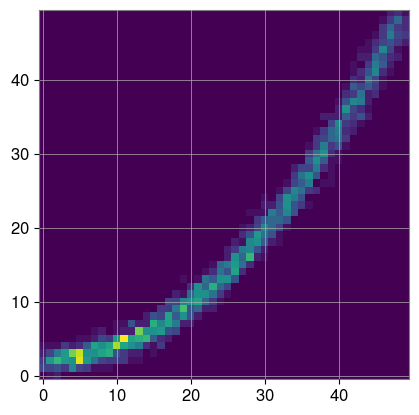

Data generated and histogram computed.
(50, 50)
Statistics for Depth-based Alpha:
Tree posterior/area - Min: 0.064, Max: 18874.368
Tree posterior/area - Mean: 2273.333


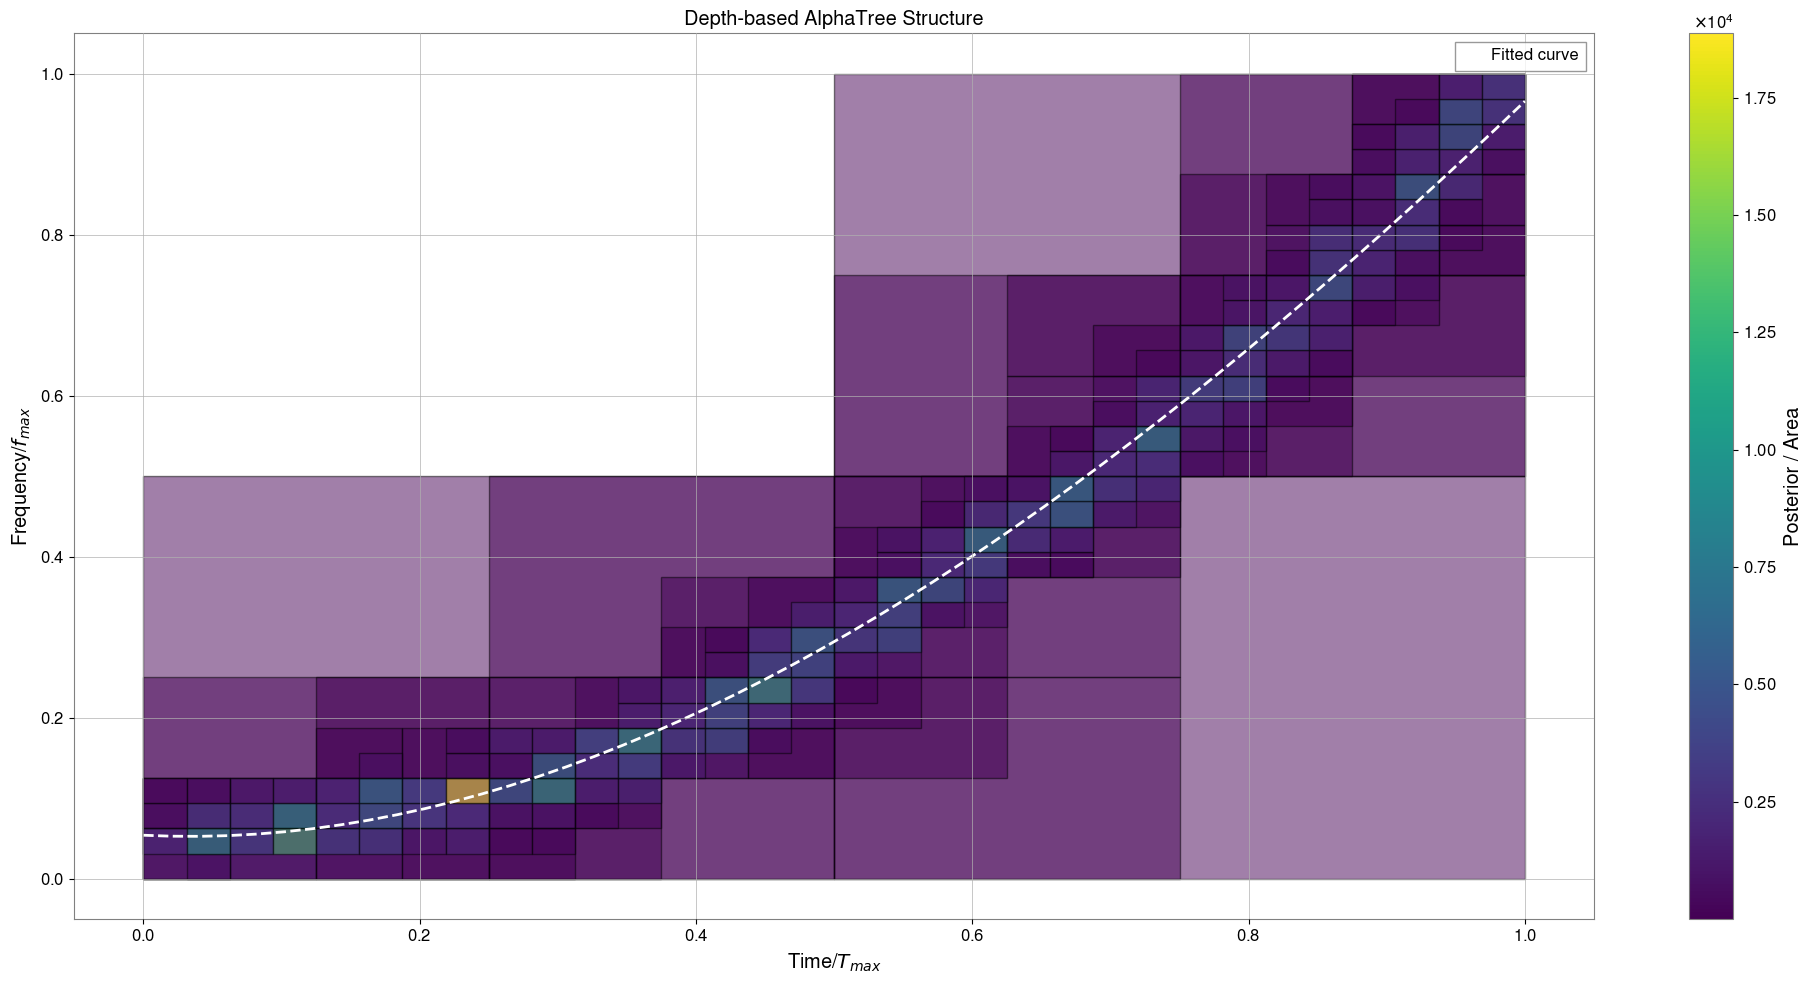

[0.0540762  0.0528735  0.05271113 0.05357537 0.05545248
 0.05832876 0.06219047 0.06702389 0.07281531 0.07955099
 0.08721721 0.09580026 0.10528641 0.11566193 0.1269131
 0.1390262  0.15198751 0.1657833  0.18039985 0.19582344
 0.21204034 0.22903684 0.2467992  0.26531371 0.28456664
 0.30454428 0.32523289 0.34661875 0.36868814 0.39142735
 0.41482263 0.43886028 0.46352657 0.48880778 0.51469018
 0.54116005 0.56820367 0.59580731 0.62395725 0.65263977
 0.68184115 0.71154766 0.74174558 0.77242119 0.80356076
 0.83515057 0.8671769  0.89962603 0.93248422 0.96573777]


In [174]:
class AdaptiveBivariatePolyaTreeMultiAlpha:
    def __init__(self, base_depth=4, max_depth=12, density_threshold=0.0001, min_mass=0.0001,   
                 alpha1=0.5, beta1=0.5, alpha2=0.5, beta2=0.5, gamma=2.0,   
                 domain=((0, 1), (0, 1)), kind=None):  
        self.base_depth = base_depth  
        self.max_depth = max_depth  
        self.density_threshold = density_threshold  
        self.min_mass = min_mass  
        # Parameters for x-direction Beta  
        self.alpha1 = alpha1  
        self.beta1 = beta1  
        # Parameters for y-direction Beta  
        self.alpha2 = alpha2  
        self.beta2 = beta2  
        self.gamma = gamma  
        self.domain = domain  
        self.counts = {}  
        self.counts[()] = 0  
        self.total_mass = 0
        self.kind=kind
    def _compute_beta_probability(self, count, total, alpha, beta, depth):  
        """Compute Beta posterior probability for a single direction"""  
        c = self.gamma  
        depth_factor = c ** depth  
        if self.kind == 'depth':
            #alpha = alpha * (1 +  depth / self.max_depth)
            alpha=1
        elif self.kind == 'density':
            alpha = alpha * (1 + beta * np.exp(-self.gamma * count/total))
        elif self.kind == 'curvature':
            alpha = alpha * (1 + 1.0 * abs(depth * count/total))
        elif self.kind == 'hybrid':
            alpha = alpha * (1 + beta * np.exp(-self.gamma * count/total))
        post_alpha = alpha * depth_factor + count/total  
        post_beta = alpha * depth_factor + (1 - count/total)  
        
        return post_alpha / (post_alpha + post_beta)
        
    def _compute_bivariate_density(self, node):  
        (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)  
        x_min, x_max = self.domain[0]  
        y_min, y_max = self.domain[1]  
          
        area_tot = (x_max - x_min) * (y_max - y_min)  
        area = (x_right - x_left) * (y_top - y_bottom)  
        count = self.counts.get(node, 0)  
        depth = len(node)  
          
        # Compute effective depth in each direction  
        depth_x = np.log2((x_max - x_min)/(x_right - x_left))  
        depth_y = np.log2((y_max - y_min)/(y_top - y_bottom))  
          
        # Compute probabilities for both directions  
        prob_x = self._compute_beta_probability(  
            count, self.total_mass, self.alpha1, self.beta1, depth_x)  
        prob_y = self._compute_beta_probability(  
            count, self.total_mass, self.alpha2, self.beta2, depth_y)
        joint_density = prob_x * prob_y  
          
        return joint_density if area > 0 else 0
    
    def _get_quadrant(self, x, y, x_mid, y_mid):
        if x <= x_mid:
            return 0 if y <= y_mid else 1
        else:
            return 2 if y <= y_mid else 3
        
    def _should_split(self, node, mass, input_pixel_size):  
        if len(node) >= self.max_depth:  
            return False  
              
        (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)  
        node_width = x_right - x_left  
        node_height = y_top - y_bottom  
          
        if node_width/2 < input_pixel_size[0] or node_height/2 < input_pixel_size[1]:  
            return False  
              
        if len(node) < self.base_depth:  
            return True  
              
        density = self._compute_bivariate_density(node)  
        return (mass >= self.min_mass * self.total_mass and   
                density >= self.density_threshold and   
                len(node) < self.max_depth)
    
    def _get_node_bounds(self, node):
        x_left, x_right = self.domain[0]
        y_bottom, y_top = self.domain[1]
        for q in node:
            x_mid = (x_left + x_right) / 2.0
            y_mid = (y_bottom + y_top) / 2.0
            if q in [0, 1]:
                x_right = x_mid
            else:
                x_left = x_mid
            if q in [0, 2]:
                y_top = y_mid
            else:
                y_bottom = y_mid
        return (x_left, x_right), (y_bottom, y_top)
    
    def _compute_local_density(self, node):
        (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)
        x_min, x_max = self.domain[0]
        y_min, y_max = self.domain[1]
        area_tot = (x_max - x_min)*(y_max-y_min)
        area = (x_right - x_left) * (y_top - y_bottom)
        count = self.counts.get(node, 0)
        coef_prob = count / (self.total_mass * area)
        depth = len(node)
        depth1 = np.log(area_tot/area)/np.log(4.0)
        c=3.0
        #post_alpha = self.alpha0 * (c ** depth1) + count/self.total_mass
        #post_beta = self.beta * (c ** depth1) + (1 - count/self.total_mass) 
        
        # Compute posterior mean
        #posterior_mean = post_alpha / (post_alpha + post_beta)
        
        return count / (self.total_mass * area) if area > 0 else 0
        #return posterior_mean if area > 0 else 0
    
    def _should_split1(self, node, mass, input_pixel_size):
        if len(node) >= self.max_depth:
            return False
            
        # Get current node dimensions
        (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)
        node_width = x_right - x_left
        node_height = y_top - y_bottom
        
        # Check if splitting would create cells smaller than input pixels
        if node_width/2 < input_pixel_size[0] or node_height/2 < input_pixel_size[1]:
            return False
            
        if len(node) < self.base_depth:
            return True
            
        density = self._compute_local_density(node)
        return (mass >= self.min_mass * self.total_mass and 
                density >= self.density_threshold and 
                len(node) < self.max_depth)
    
    def _update_counts_from_histogram(self, hist_2d, input_pixel_size):
        """Update counts using 2D histogram data"""
        self.total_mass = np.sum(hist_2d)
        
        # Get histogram dimensions
        ny, nx = hist_2d.shape
        dx = (self.domain[0][1] - self.domain[0][0]) / nx
        dy = (self.domain[1][1] - self.domain[1][0]) / ny
        
        points_to_process = [((), hist_2d)]
        while points_to_process:
            node, node_hist = points_to_process.pop(0)
            
            # Compute mass in current node
            self.counts[node] = np.sum(node_hist)
            
            if self._should_split(node, self.counts[node], input_pixel_size):
                # Split histogram into quadrants
                ny, nx = node_hist.shape
                mid_y, mid_x = ny//2, nx//2
                
                quadrants = {
                    0: node_hist[:mid_y, :mid_x],
                    1: node_hist[mid_y:, :mid_x],
                    2: node_hist[:mid_y, mid_x:],
                    3: node_hist[mid_y:, mid_x:]
                }
                
                for q in range(4):
                    if np.sum(quadrants[q]) > 0:  # Only process non-empty quadrants
                        points_to_process.append((node + (q,), quadrants[q]))
    
    def fit(self, hist_2d):
        """Fit the Polya tree using a 2D histogram"""
        # Calculate input pixel size
        print(hist_2d.shape)
        ny, nx = hist_2d.shape
        dx = (self.domain[0][1] - self.domain[0][0]) / nx
        dy = (self.domain[1][1] - self.domain[1][0]) / ny
        input_pixel_size = (dx, dy)
        
        self._update_counts_from_histogram(hist_2d, input_pixel_size)
        return self

# Test the modified class with a simple example
if __name__ == "__main__":
    # Create a simple test histogram
    nx, ny = 50, 50
    x = np.linspace(0, 1, nx)
    y = np.linspace(0, 1, ny)
    X, Y = np.meshgrid(x, y)
    
    # Create a simple gaussian bump
    hist_2d = np.exp(-((X-0.5)**2 + (Y-0.5)**2)/0.1)
    
    # Initialize and fit the tree
    tree = AdaptiveBivariatePolyaTreeMultiAlpha(
        base_depth=2,
        max_depth=8,
        density_threshold=0.01,
        min_mass=0.01
    )
    tree.fit(hist_2d)
    
    # Print some basic information
    print("Total mass:", tree.total_mass)
    print("Number of nodes:", len(tree.counts))
    
    # Plot the input histogram
    import matplotlib.pyplot as plt
    
    plt.figure(figsize=(10, 4))
    
    plt.subplot(121)
    plt.imshow(hist_2d, origin='lower', extent=[0, 1, 0, 1])
    plt.colorbar(label='Density')
    plt.title('Input Histogram')
    
    # Plot the node structure
    plt.subplot(122)
    for node in tree.counts:
        if node:  # Skip root node
            (x_left, x_right), (y_bottom, y_top) = tree._get_node_bounds(node)
            plt.plot([x_left, x_right], [y_bottom, y_bottom], 'k-', alpha=0.5)
            plt.plot([x_left, x_right], [y_top, y_top], 'k-', alpha=0.5)
            plt.plot([x_left, x_left], [y_bottom, y_top], 'k-', alpha=0.5)
            plt.plot([x_right, x_right], [y_bottom, y_top], 'k-', alpha=0.5)
    
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.title('Tree Structure')
    
    plt.tight_layout()
    plt.show()

def generate_chirp_data(n_points=2000, fake=True):
    if fake:
        # Generate clean theoretical curve first
        t_clean = np.linspace(0, 1, n_points)
        f_clean = 20 + 980 * t_clean**2

        # Generate noisy data
        t = t_clean + 0.02 * np.random.randn(n_points)
        f = f_clean + 20 * np.random.randn(n_points)

        # Normalize both clean and noisy data
        t = (t - t.min()) / (t.max() - t.min())
        f = (f - f.min()) / (f.max() - f.min())
        t_clean = (t_clean - t_clean.min()) / (t_clean.max() - t_clean.min())
        f_clean = (f_clean - f_clean.min()) / (f_clean.max() - f_clean.min())

        return np.column_stack([t, f]), np.column_stack([t_clean, f_clean])
    
        

class AdaptiveBivariatePolyaTreeMultiAlphaExtended(AdaptiveBivariatePolyaTreeMultiAlpha):
    def compute_posteriors_alphas(self, resolution=(50,50)):
        # Create grid centers using resolution
        nx, ny = resolution
        x = np.linspace(self.domain[0][0], self.domain[0][1], nx)
        y = np.linspace(self.domain[1][0], self.domain[1][1], ny)
        X, Y = np.meshgrid(x, y)
        
        densities = np.zeros_like(X)
        alpha_maps = {
            'depth': np.zeros_like(X),
            'density': np.zeros_like(X),
            'curvature': np.zeros_like(X),
            'hybrid': np.zeros_like(X)
        }
        normalized_alpha_maps = {
            'depth': np.zeros_like(X),
            'density': np.zeros_like(X),
            'curvature': np.zeros_like(X),
            'hybrid': np.zeros_like(X)
        }
        pixel_areas = np.zeros_like(X)
        
        for i in range(X.shape[0]):
            for j in range(X.shape[1]):
                x_pt, y_pt = X[i,j], Y[i,j]
                node = ()
                prob = 1.0
                while True:
                    (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)
                    area = (x_right - x_left) * (y_top - y_bottom)
                    pixel_areas[i,j] = area
                    
                    local_density = self._compute_local_density(node)
                    depth = len(node)
                    
                    # Compute different alpha definitions
                    alpha_depth = self.alpha0 * (1 + self.lam * depth / self.max_depth)
                    alpha_density = self.alpha0 * (1 + self.beta * np.exp(-self.gamma * local_density))
                    alpha_curvature = self.alpha0 * (1 + self.eta * abs(depth * local_density))
                    alpha_hybrid = alpha_depth * (1 + self.beta * np.exp(-self.gamma * local_density))
                    
                    # Store the alpha values
                    alpha_maps['depth'][i,j] = alpha_depth
                    alpha_maps['density'][i,j] = alpha_density
                    alpha_maps['curvature'][i,j] = alpha_curvature
                    alpha_maps['hybrid'][i,j] = alpha_hybrid
                    
                    normalized_alpha_maps['depth'][i,j] = alpha_depth / area if area>0 else 0
                    normalized_alpha_maps['density'][i,j] = alpha_density / area if area>0 else 0
                    normalized_alpha_maps['curvature'][i,j] = alpha_curvature / area if area>0 else 0
                    normalized_alpha_maps['hybrid'][i,j] = alpha_hybrid / area if area>0 else 0
                    
                    # Decide to split or not
                    mass = self.counts.get(node, 0)
                    input_dx = (self.domain[0][1] - self.domain[0][0]) / resolution[0]
                    input_dy = (self.domain[1][1] - self.domain[1][0]) / resolution[1]
                    input_pixel_size = (input_dx, input_dy)
                    
                    if not self._should_split(node, mass, input_pixel_size):
                        densities[i,j] = prob * local_density
                        break
                    
                    x_mid = (x_left + x_right)/2.0
                    y_mid = (y_bottom + y_top)/2.0
                    quadrant = self._get_quadrant(x_pt, y_pt, x_mid, y_mid)
                    node = node + (quadrant,)
                    prob /= 4.0

        return X, Y, densities, alpha_maps, normalized_alpha_maps, pixel_areas

# Generate data
points, clean_points = generate_chirp_data(n_points=2000)
nx, ny = 50, 50
hist_2d, x_edges, y_edges = np.histogram2d(
    points[:, 0], points[:, 1],
    bins=[nx, ny],
    range=[[0, 1], [0, 1]]
)
plt.imshow(hist_2d.T, origin='lower')
plt.show()
hist_2d = hist_2d.T
print("Data generated and histogram computed.")

from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline

def compute_tree_posteriors(tree, alpha_type='depth'):
    """Compute posteriors for each node using specified alpha type"""
    posterior_values = []
    rectangles = []
    points_for_kde = []
    
    for node in tree.counts:
        if node:
            (x_left, x_right), (y_bottom, y_top) = tree._get_node_bounds(node)
            area = (x_right - x_left) * (y_top - y_bottom)
            local_density = tree._compute_local_density(node)
            depth = len(node)
            
            if alpha_type == 'depth':
                alpha = tree.alpha1 * (1 +  depth / tree.max_depth)
            elif alpha_type == 'density':
                alpha = tree.alpha1 * (1 + tree.beta1 * np.exp(-tree.gamma * local_density))
            elif alpha_type == 'curvature':
                alpha = tree.alpha1 * (1 +  abs(depth * local_density))
            elif alpha_type == 'hybrid':
                alpha_depth = tree.alpha1 * (1 +  depth / tree.max_depth)
                alpha = alpha_depth * (1 + tree.beta1 * np.exp(-tree.gamma * local_density))
            alpha = tree.alpha1
            posterior = local_density * alpha
            posterior_per_area = posterior / area if area > 0 else 0
            
            # Store center point of the rectangle
            center_x = (x_left + x_right) / 2
            center_y = (y_bottom + y_top) / 2
            
            posterior_values.append(posterior_per_area)
            rectangles.append((x_left, y_bottom, x_right - x_left, y_top - y_bottom, posterior_per_area))
            points_for_kde.append([center_x, center_y, posterior_per_area])
            
    return np.array(posterior_values), rectangles, np.array(points_for_kde)

def extract_high_posterior_curve(points_for_kde, n_bins=20, threshold_percentile=90):
    """Extract the highest posterior frequency at each time bin"""
    times = points_for_kde[:, 0]
    freqs = points_for_kde[:, 1]
    posteriors = points_for_kde[:, 2]
    
    # Only consider points with high posterior (above threshold)
    threshold = np.percentile(posteriors, threshold_percentile)
    high_posterior_mask = posteriors >= threshold
    
    times_high = times[high_posterior_mask]
    freqs_high = freqs[high_posterior_mask]
    posteriors_high = posteriors[high_posterior_mask]
    
    # Create time bins and find highest posterior frequency in each bin
    time_bins = np.linspace(0, 1, n_bins+1)
    time_centers = (time_bins[1:] + time_bins[:-1]) / 2
    freq_peaks = []
    
    for i in range(n_bins):
        mask = (times_high >= time_bins[i]) & (times_high < time_bins[i+1])
        if np.any(mask):
            # Get frequency with highest posterior in this bin
            idx = np.argmax(posteriors_high[mask])
            freq_peaks.append(freqs_high[mask][idx])
        else:
            freq_peaks.append(np.nan)
    
    # Remove NaN values
    valid_mask = ~np.isnan(freq_peaks)
    time_centers = time_centers[valid_mask]
    freq_peaks = np.array(freq_peaks)[valid_mask]
    
    # Fit a smooth curve through the peaks
    if len(time_centers) > 3:  # Need at least 4 points for cubic spline
        spl = UnivariateSpline(time_centers, freq_peaks, k=3, s=0.01)
        return lambda x: spl(x)
    else:
        return None

# Create figure with 2x4 subplots
fig, axes = plt.subplots(1, 1, figsize=(20, 10))

alpha_types = ['depth']
titles = ['Depth-based Alpha', 'Density-based Alpha', 
          'Curvature-based Alpha', 'Hybrid Alpha']

# Create evaluation grid
grid_size = 50
x_grid = np.linspace(0, 1, grid_size)
y_grid = np.linspace(0, 1, grid_size)
X, Y = np.meshgrid(x_grid, y_grid)
positions = np.vstack([X.ravel(), Y.ravel()])
curves = []
for idx, (alpha_type, title) in enumerate(zip(alpha_types, titles)):
    # Compute posteriors
    tree_ext = AdaptiveBivariatePolyaTreeMultiAlphaExtended(
        base_depth=4,
        max_depth=16,
        density_threshold=0.00001,
        min_mass=0.00001,
        kind=alpha_type
    )
    tree_ext.fit(hist_2d)
    posterior_values, rectangles, points_for_kde = compute_tree_posteriors(tree_ext, alpha_type)
    #print(rectangles, title)
    # Extract high posterior curve
    curve_fit = extract_high_posterior_curve(points_for_kde)
    
    # Original Tree Plot (top row)
    ax = axes
    
    # Plot histogram background
    #ax.imshow(hist_2d, origin='lower', extent=[0, 1, 0, 1], 
    #          aspect='auto', cmap='gray', alpha=0.3)
    
    # Normalize and plot rectangles
    vmin, vmax = np.min(posterior_values), np.max(posterior_values)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    
    for rect_info in rectangles:
        x, y, w, h, val = rect_info
        rect = plt.Rectangle((x, y), w, h,
                           facecolor=plt.cm.viridis(norm(val)),
                           edgecolor='black',
                           alpha=0.5)
        ax.add_patch(rect)
    
    # Add fitted curve and theoretical curve
    if curve_fit is not None:
        y_fit = curve_fit(x_grid)
        ax.plot(x_grid, y_fit, 'w--', linewidth=2, label='Fitted curve')
    #ax.plot(clean_points[:,0], clean_points[:,1], 'r-', 
    #        linewidth=2, label='Theoretical curve')
    curves.append(y_fit)
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='viridis'), 
                ax=ax, label='Posterior / Area')
    ax.set_xlabel('Time/$T_{max}$')
    ax.set_ylabel('Frequency/$f_{max}$')
    ax.set_title(f'{title}\
Tree Structure')
    ax.legend()
    
    # KDE Plot (bottom row)
    #ax_kde = axes[1, idx]
    
    # Compute and plot KDE
    '''
    xy_points = points_for_kde[:, :2]
    z_values = points_for_kde[:, 2]
    kde = gaussian_kde(xy_points.T, weights=z_values)
    Z = kde(positions).reshape(X.shape)
    
    im = ax_kde.imshow(Z, extent=[0, 1, 0, 1], origin='lower', 
                      aspect='auto', cmap='viridis')
    plt.colorbar(im, ax=ax_kde, label='KDE Density')
    
    # Add fitted curve and theoretical curve
    if curve_fit is not None:
        ax_kde.plot(x_grid, y_fit, 'w--', linewidth=2, label='Fitted curve')
    ax_kde.plot(clean_points[:,0], clean_points[:,1], 'r-', 
                linewidth=2, label='Theoretical curve')
    
    ax_kde.set_xlabel('Time')
    ax_kde.set_ylabel('Frequency')
    ax_kde.set_title(f'{title}\
Gaussian KDE')
    ax_kde.legend()
'''
    # Print statistics
    print(f"\
Statistics for {title}:")
    print(f"Tree posterior/area - Min: {vmin:.3f}, Max: {vmax:.3f}")
    print(f"Tree posterior/area - Mean: {np.mean(posterior_values):.3f}")

plt.tight_layout()
plt.show()
for i in range (0, len(curves)):
    print(curves[i])

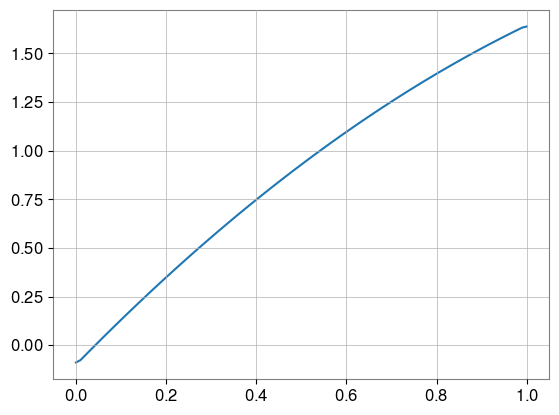

Shape of X_poly: (100, 6)
Discovered equation terms (using OMP):
-0.101 * t
1.186 * t^2
-0.209 * t^3

OMP R² score: 1.0


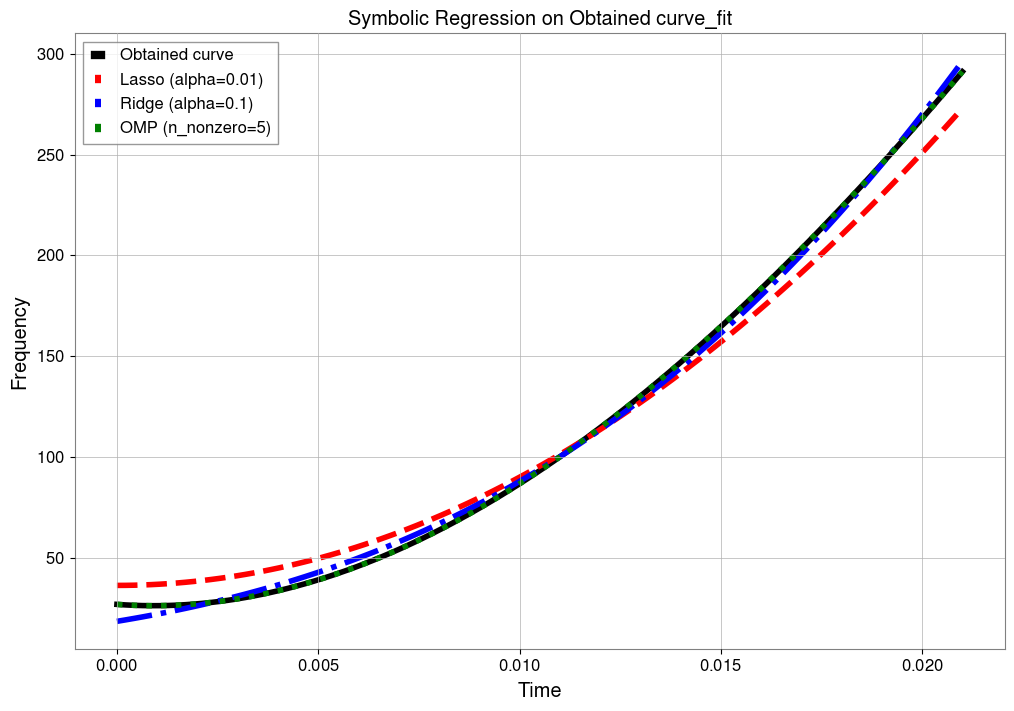


Lasso coefficients:
t^2: 0.7845027332030864

Ridge coefficients:
t: 0.2290099069582403
t^2: 0.39304271897160725
t^3: 0.26513989154994866
t^4: 0.0924054433083445
t^5: -0.05878620232118656

OMP coefficients:
t: -0.10105563624677377
t^2: 1.1861036421358324
t^3: -0.2091817835795064

R² scores for predicting the second derivative:
Lasso: -0.27346946906642544
Ridge: -0.21312413187060764
OMP: -0.2134117229377963


In [181]:
import numpy as np  
import matplotlib.pyplot as plt  
from sklearn.linear_model import Lasso, Ridge, OrthogonalMatchingPursuit  
from sklearn.preprocessing import PolynomialFeatures  
from sklearn.metrics import r2_score  
  
 
  
# Compute first and second derivatives of y_sample numerically    
y_der = np.gradient(y_sample, t_sample)  
dt = t_sample[1] - t_sample[0]
phase = np.cumsum(y_sample*dt)
#y_der2 = np.gradient(y_der, t_sample)  
plt.plot(t_sample, y_der)
plt.show()
# Create polynomial features (degree 5)    
poly_degree = 5  
poly = PolynomialFeatures(degree=poly_degree, include_bias=True)  
  
# Combine the independent variables: time, function value, and first derivative    
X = t_sample.reshape(-1, 1)
X_poly = poly.fit_transform(X)  
  
# Check shape of polynomial feature matrix  
print("Shape of X_poly:", X_poly.shape)  
  
# Prepare regression models    
n_features = X_poly.shape[1]  
n_nonzero_coefs = min(5, n_features)  
  
lasso_alpha = 0.01  
ridge_alpha = 0.1  
  
lasso = Lasso(alpha=lasso_alpha, max_iter=10000)  
ridge = Ridge(alpha=ridge_alpha)  
omp = OrthogonalMatchingPursuit(n_nonzero_coefs=n_nonzero_coefs)  
  
# Fit the models on the sampled data  
lasso.fit(X_poly, y_sample)  
ridge.fit(X_poly, y_sample)  
omp.fit(X_poly, y_sample)  
  
# Get feature names from polynomial features    
feature_names = poly.get_feature_names_out(['t'])  
significant_terms = [(name, coef) for name, coef in zip(feature_names, omp.coef_) if abs(coef) > 1e-10]  
  
print("Discovered equation terms (using OMP):")  
for term, coef in significant_terms:  
    print(f"{coef:.3f} * {term}")  
  
# Use y_der2 as target for calculating R² score  
print("\nOMP R² score:", omp.score(X_poly, y_sample))  
  
# Generate predictions using these models    
y_lasso = lasso.predict(X_poly)  
y_ridge = ridge.predict(X_poly)  
y_omp   = omp.predict(X_poly)  
  
# Plot the symbolic regression results alongside the original curve_fit  
plt.figure(figsize=(12, 8))  
plt.plot(t_sample*0.021, y_sample*302, 'k', linewidth=4, label='Obtained curve')  
plt.plot(t_sample*0.021, y_lasso*302, 'r--', linewidth=4, label='Lasso (alpha=' + str(lasso_alpha) + ')')  
plt.plot(t_sample*0.021, y_ridge*302, 'b-.', linewidth=4, label='Ridge (alpha=' + str(ridge_alpha) + ')')  
plt.plot(t_sample*0.021, y_omp*302, 'g:', linewidth=4, label='OMP (n_nonzero=' + str(n_nonzero_coefs) + ')')  
plt.xlabel('Time')  
plt.ylabel('Frequency')  
plt.title('Symbolic Regression on Obtained curve_fit')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# Optionally, print the coefficients for each regression model  
print("\nLasso coefficients:")  
for name, coef in zip(feature_names, lasso.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
            
print("\nRidge coefficients:")  
for name, coef in zip(feature_names, ridge.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
            
print("\nOMP coefficients:")  
for name, coef in zip(feature_names, omp.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
            
# Print R² scores for each method (Note: comparing predictions on y_der2)  
print("\nR² scores for predicting the second derivative:")  
print("Lasso: " + str(r2_score(y_der, y_lasso)))  
print("Ridge: " + str(r2_score(y_der, y_ridge)))  
print("OMP: " + str(r2_score(y_der, y_omp)))  

In [131]:
import sympy as sp  
  
# Define symbolic variables; note: we use 'df' to represent 'df/dt' for simplicity  
t, phi, f = sp.symbols('t phi f')  
  
def create_symbolic_expr(coef, feature_names):  
    expr = 0  
    for name, c in zip(feature_names, coef):  
        if abs(c) > 1e-10:  # Only include significant terms  
            # Clean up the feature name:  
            term = name.replace('^', '**')   # Handle power notation  
            term = term.replace(' ', '*')     # Handle multiplication  
            # Create the sympy expression term using sympify  
            term_expr = sp.sympify("(" + str(c) + ")*(" + term + ")")  
            expr += term_expr  
    return expr  
  
# Create symbolic expressions for each model  
omp_expr = create_symbolic_expr(omp.coef_, feature_names)  
lasso_expr = create_symbolic_expr(lasso.coef_, feature_names)  
ridge_expr = create_symbolic_expr(ridge.coef_, feature_names)  
  
# Create lambda functions that accept (t, f, df) as inputs  
f_omp = sp.lambdify((t, phi, f), omp_expr, 'numpy')  
f_lasso = sp.lambdify((t, phi, f), lasso_expr, 'numpy')  
f_ridge = sp.lambdify((t, phi, f), ridge_expr, 'numpy')  
  
print("Symbolic expressions for d²f/dt²:")  
print("\nOMP expression:")  
print(omp_expr)  
print("\nLasso expression:")  
print(lasso_expr)  
print("\nRidge expression:")  
print(ridge_expr)  
  
# Test the lambda functions with some sample points  
test_points = [[0.1, 0.2, 0.3],  
               [0.4, 0.5, 0.6]]  
  
print("\nTesting lambda functions at sample points:")  
for point in test_points:  
    t_val, ph_val, f_val = point  
    print("\nAt (t={:.1f}, f={:.1f}):".format(t_val, ph_val, f_val))  
    print("OMP: d²f/dt² =", f_omp(t_val, ph_val, f_val))  
    print("Lasso: d²f/dt² =", f_lasso(t_val, ph_val, f_val))  
    print("Ridge: d²f/dt² =", f_ridge(t_val, ph_val, f_val))  

Symbolic expressions for d²f/dt²:

OMP expression:
-0.052134613916473886*f**5 - 0.3254208619621029*f*t - 0.3816929654931261*f + 0.11699861959244515*t**5 + 2.313579891508742*t

Lasso expression:
1.6260017383249454*t

Ridge expression:
0.09664056250660032*f**5 + 0.04858288736543583*f**4*phi + 0.07139792990218795*f**4*t + 0.023687817981686895*f**4 + 0.02267408128642786*f**3*phi**2 + 0.04081868455597718*f**3*phi*t + 0.024505280539200487*f**3*phi + 0.0390724794820752*f**3*t**2 - 0.015345218013718161*f**3*t - 0.06844805200057648*f**3 + 0.010115934221090613*f**2*phi**3 + 0.020385426779670444*f**2*phi**2*t + 0.014904725031062303*f**2*phi**2 + 0.03053426491778377*f**2*phi*t**2 + 0.011185293259875762*f**2*phi*t - 0.009341841018565177*f**2*phi - 0.0008978417522730995*f**2*t**3 - 0.05960327856160175*f**2*t**2 - 0.09838926473117512*f**2*t - 0.08900735063590356*f**2 + 0.0043799684030547134*f*phi**4 + 0.009480257346634912*f*phi**3*t + 0.007670234877976437*f*phi**3 + 0.01722747891726647*f*phi**2*t**2 

In [133]:
def helmholtz_conditions(f_expr):  
    # f_expr is in the form f(t,q,dq) such that d²q/dt² = f.  
    # For a second order ODE to be variational, the following simplified Helmholtz conditions (among others)  
    # must hold:  
      
    # Condition 1: f_{,dq dq} == 0  
    H1 = sp.diff(f_expr, f, 2)  
      
    # Condition 2: f_{,q} = f_{,dq,t}  
    H2 = sp.diff(f_expr, phi) - sp.diff(sp.diff(f_expr, f), t)  
      
    # Condition 3: f_{,t} = - f_{,q,dq}  
    H3 = sp.diff(f_expr, t) + sp.diff(sp.diff(f_expr, phi), f)  
      
    return sp.simplify(H1), sp.simplify(H2), sp.simplify(H3)  
  
# Check the Helmholtz conditions on our equation expression:  
for expression in (lasso_expr, ridge_expr, omp_expr):
    H1, H2, H3 = helmholtz_conditions(expression)  

    print("Helmholtz Conditions for the equation:")  
    print("\nCondition 1 (should be 0):")  
    print(sp.simplify(H1))  
    print(H1)
    print("\nCondition 2 (should be 0):")  
    print(sp.simplify(H2))  
    print("\nCondition 3 (should be 0):")  
    print(sp.simplify(H3)) 
    

Helmholtz Conditions for the equation:

Condition 1 (should be 0):
0
0

Condition 2 (should be 0):
0

Condition 3 (should be 0):
1.6260017383249454
Helmholtz Conditions for the equation:

Condition 1 (should be 0):
1.932811250132006*f**3 + 0.58299464838523*f**2*phi + 0.8567751588262554*f**2*t + 0.28425381578024274*f**2 + 0.1360444877185672*f*phi**2 + 0.2449121073358631*f*phi*t + 0.14703168323520292*f*phi + 0.234434876892451*f*t**2 - 0.092071308082308966*f*t - 0.4106883120034589*f + 0.020231868442181226*phi**3 + 0.040770853559340888*phi**2*t + 0.029809450062124606*phi**2 + 0.06106852983556754*phi*t**2 + 0.022370586519751524*phi*t - 0.01868368203713035*phi - 0.001795683504546199*t**3 - 0.1192065571232035*t**2 - 0.1967785294623502*t - 0.1780147012718071
1.932811250132006*f**3 + 0.58299464838523*f**2*phi + 0.8567751588262554*f**2*t + 0.28425381578024274*f**2 + 0.1360444877185672*f*phi**2 + 0.2449121073358631*f*phi*t + 0.14703168323520292*f*phi + 0.234434876892451*f*t**2 - 0.092071308082308

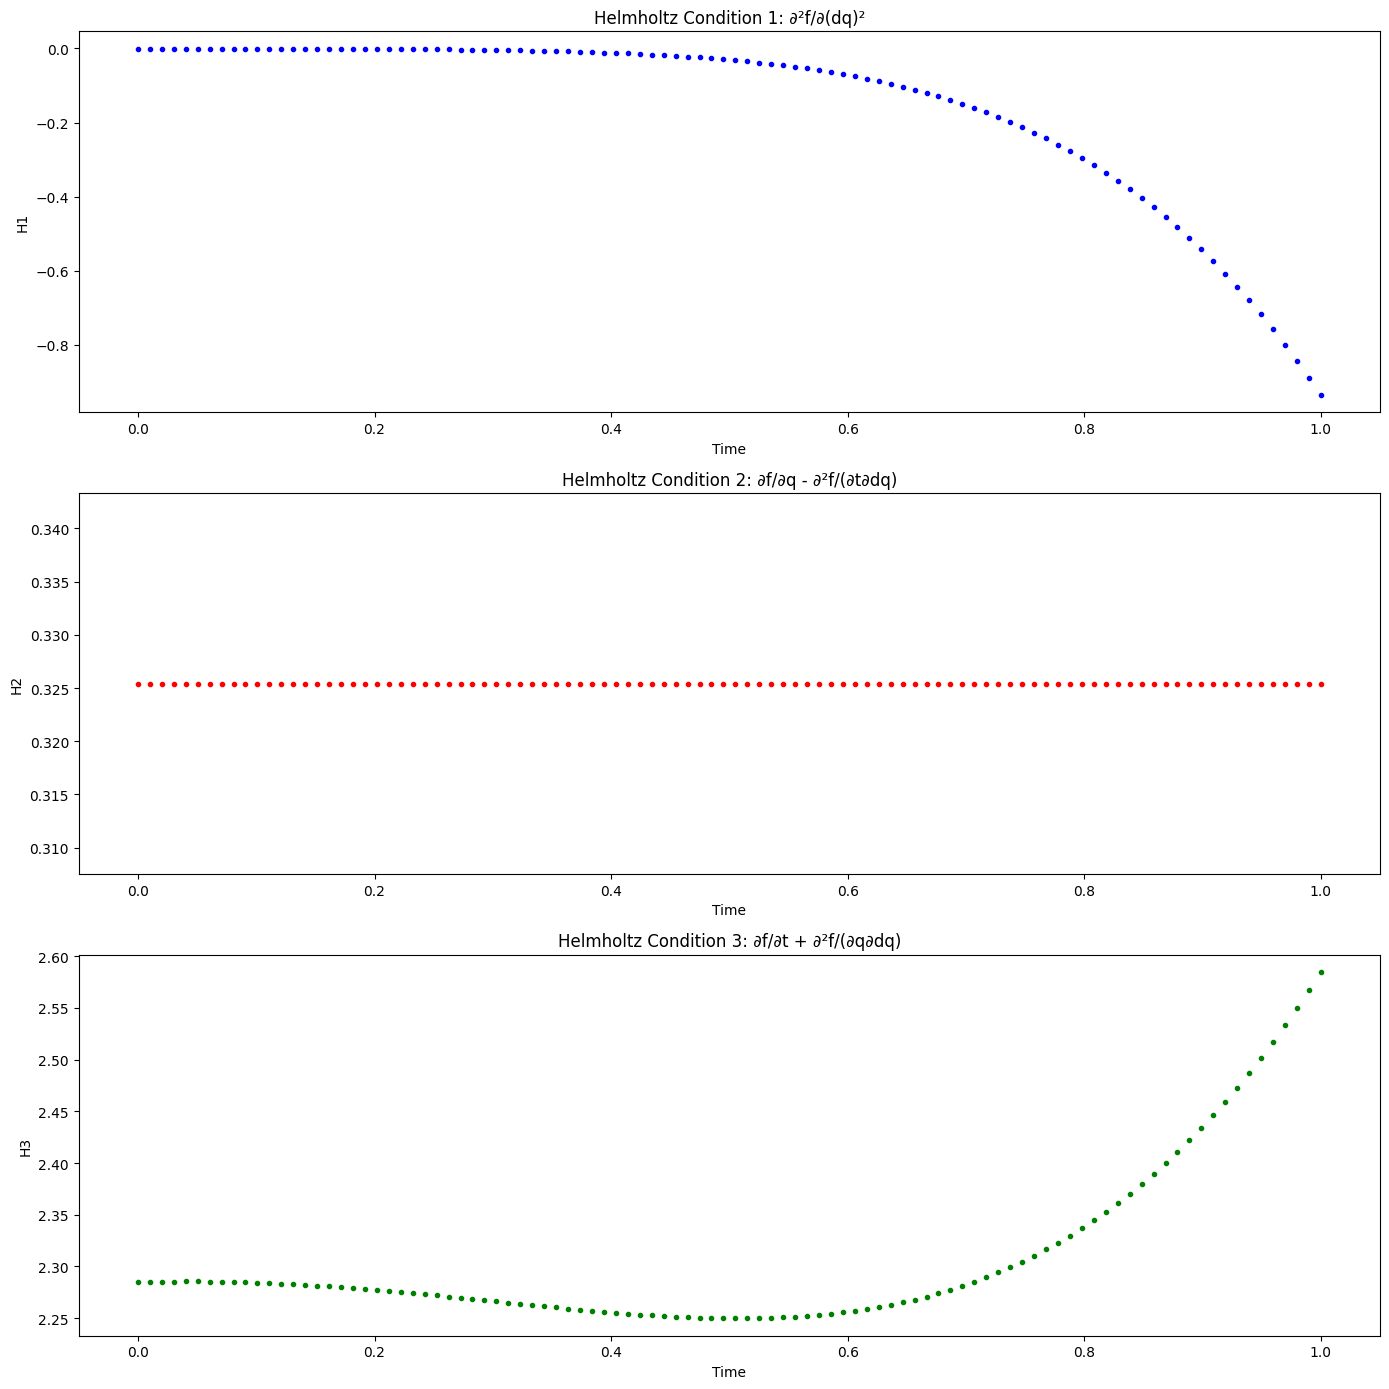

H1: min = -0.93534263978273 max = -0.0006726253531593079 mean = -0.15785642802941052
H2: min = 0.3254208619621029 max = 0.3254208619621029 mean = 0.3254208619621029
H3: min = 2.249744060611835 max = 2.584726759347013 mean = 2.3078540729809416


In [137]:
H1_func = sp.lambdify((t, phi, f), H1, modules='numpy')  
H2_func = sp.lambdify((t, phi, f), H2, modules='numpy')  
H3_func = sp.lambdify((t, phi, f), H3, modules='numpy')  
  
# Suppose you have data arrays:  
# For example, using the t_sample, y_sample and y_der arrays from your earlier code.  
# Here, we alias them to t_data, q_data, and dq_data:  
# (Adjust these names if your data arrays are named differently)  
t_data = t_sample          # time array  
q_data = phase          # sample data (you can think of it as q)  
dq_data = y_sample            # first derivative data (dq)  
  
# Evaluate the conditions over your entire dataset.  
H1_eval = H1_func(t_data, q_data, dq_data)
H2_eval = H2_func(t_data, q_data, dq_data)  
H3_eval = H3_func(t_data, q_data, dq_data)  
def ensure_array(H_value, shape):  
    # If H_value is a scalar, create an array full of that value.  
    if np.isscalar(H_value):  
        return np.full(shape, H_value, dtype=float)  
    else:  
        return np.array(H_value, dtype=float)  
  

H1_values = ensure_array(H1_eval, t_data.shape)  
H2_values = ensure_array(H2_eval, t_data.shape)  
H3_values = ensure_array(H3_eval, t_data.shape)
# Plotting the conditions over the dataset  
plt.figure(figsize=(14, 14))  
  
plt.subplot(3, 1, 1)  
plt.plot(t_data, H1_values, 'b.')  
plt.xlabel('Time')  
plt.ylabel('H1')  
plt.title('Helmholtz Condition 1: ∂²f/∂(dq)²')  
  
plt.subplot(3, 1, 2)  
plt.plot(t_data, H2_values, 'r.')  
plt.xlabel('Time')  
plt.ylabel('H2')  
plt.title('Helmholtz Condition 2: ∂f/∂q - ∂²f/(∂t∂dq)')  
  
plt.subplot(3, 1, 3)  
plt.plot(t_data, H3_values, 'g.')  
plt.xlabel('Time')  
plt.ylabel('H3')  
plt.title('Helmholtz Condition 3: ∂f/∂t + ∂²f/(∂q∂dq)')  
  
plt.tight_layout()  
plt.show()  
  
# Also, you can inspect statistics of these conditions to see how closely they approximate zero  
print("H1: min =", np.min(H1_values), "max =", np.max(H1_values), "mean =", np.mean(H1_values))  
print("H2: min =", np.min(H2_values), "max =", np.max(H2_values), "mean =", np.mean(H2_values))  
print("H3: min =", np.min(H3_values), "max =", np.max(H3_values), "mean =", np.mean(H3_values))  

In [ ]:
model = PySRRegressor(
        niterations=100,  # Number of iterations
        binary_operators=["+", "-", "*", "/", "^"],  # Allowed operators
        unary_operators=["exp", "log"],  # Allowed functions
        populations=20,  # Number of populations
        population_size=50,  # Size of each population
        maxsize=20,  # Maximum size of the expression
        parsimony=0.1,  # Encourages simpler models
        progress=True,  # Show progress bar
    )

    # Fit the model
    model.fit(X, y_target)
    dx_dt_pred = model.predict(X)
    #print(dx_dt_noisy.shape)
    # Plot the results
    plt.figure(figsize=(10, 6))
    plt.plot(t, dx_dt_noisy, color='blue', alpha=0.6, label='Data')
    #plt.plot(t, (-1*(-0.11657277) - 0.0018206446/(t - 1*(-0.093872644))**3/8.)*0.6961928, color='blue', alpha=0.6, label='Data')
    plt.plot(t, dx_dt_pred, color='red', linestyle='--', label=''.join(('Predicted: ', str(model.sympy()))))
    plt.xlabel('Time (t)')
    plt.ylabel('df/dt')
    plt.title('Symbolic Regression: True vs Predicted df/dt')
    plt.legend()
    plt.show()
    # Print the best symbolic expression
    print("Discovered equation:")
    print(model.sympy())

In [107]:
from sklearn.linear_model import Lasso, Ridge, OrthogonalMatchingPursuit  
from sklearn.preprocessing import PolynomialFeatures  
from sklearn.metrics import r2_score  
  
# Sample points from the obtained curve_fit  
t_sample = np.linspace(0, 1, 100)  
y_sample = curve_fit(t_sample)  
#t_sample = np.log(t_sample)
y_der = np.gradient(y_sample)
y_der2 = np.gradient(y_der)

# Create polynomial features (degree 5)  
poly_degree = 5  
poly = PolynomialFeatures(degree=poly_degree, include_bias=True)

X = np.column_stack((t_sample, y_sample, y_der))
X_poly = poly.fit_transform(X)  

# Prepare regression models
print(X_poly.shape)
n_features = X_poly.shape[1]  
n_nonzero_coefs = min(5, n_features)  # ensure valid number for OMP  
  
lasso_alpha = 0.01  
ridge_alpha = 0.1  
  
lasso = Lasso(alpha=lasso_alpha, max_iter=10000)  
ridge = Ridge(alpha=ridge_alpha)  
omp = OrthogonalMatchingPursuit(n_nonzero_coefs=n_nonzero_coefs)  
  
# Fit the models on the sampled curve data  
lasso.fit(X_poly, y_der2)  
ridge.fit(X_poly, y_der2)  
omp.fit(X_poly, y_der2)  


# Get feature names and print significant terms
feature_names = poly.get_feature_names_out(['t', 'f', "df"])
significant_terms = [(name, coef) for name, coef in zip(feature_names, omp.coef_) if abs(coef) > 1e-10]
print("Discovered equation terms:")
for term, coef in significant_terms:
    print(f"{coef:.3f} * {term}")

print("\
R² score:", omp.score(X_poly, y_true))
# Generate predictions using these models  
y_lasso = lasso.predict(X_poly)  
y_ridge = ridge.predict(X_poly)  
y_omp = omp.predict(X_poly)  
'''
# Plot the symbolic regression results alongside the original curve_fit  
plt.figure(figsize=(12, 8))  
plt.plot(t_sample, y_sample, 'k', linewidth=4, label='Obtained curve_fit (Spline)')  
plt.plot(t_sample, y_lasso, 'r--', linewidth=2, label='Lasso (alpha=' + str(lasso_alpha) + ')')  
plt.plot(t_sample, y_ridge, 'b-.', linewidth=2, label='Ridge (alpha=' + str(ridge_alpha) + ')')  
plt.plot(t_sample, y_omp, 'g:', linewidth=2, label='OMP (n_nonzero=' + str(n_nonzero_coefs) + ')')  
plt.xlabel('Time')  
plt.ylabel('Frequency')  
plt.title('Symbolic Regression on Obtained curve_fit')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# Print the coefficients for each regression model  
feature_names = poly.get_feature_names_out(['t'])  
  
print("\nLasso coefficients:")  
for name, coef in zip(feature_names, lasso.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
          
print("\nRidge coefficients:")  
for name, coef in zip(feature_names, ridge.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
          
print("\nOMP coefficients:")  
for name, coef in zip(feature_names, omp.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
          
# Print R² scores for each method  
print("\nR² scores:")  
print("Lasso: " + str(r2_score(y_sample, y_lasso)))  
print("Ridge: " + str(r2_score(y_sample, y_ridge)))  
print("OMP: " + str(r2_score(y_sample, y_omp)))  
  
# ======================  
# End of Added Symbolic Regression Section  
# ======================  '''

(100, 56)
Discovered equation terms:
0.000 * t
-0.002 * t^2
0.002 * t f
-0.001 * t^5
0.000 * f^5
R² score: -2.0186213763818


'\n# Plot the symbolic regression results alongside the original curve_fit  \nplt.figure(figsize=(12, 8))  \nplt.plot(t_sample, y_sample, \'k\', linewidth=4, label=\'Obtained curve_fit (Spline)\')  \nplt.plot(t_sample, y_lasso, \'r--\', linewidth=2, label=\'Lasso (alpha=\' + str(lasso_alpha) + \')\')  \nplt.plot(t_sample, y_ridge, \'b-.\', linewidth=2, label=\'Ridge (alpha=\' + str(ridge_alpha) + \')\')  \nplt.plot(t_sample, y_omp, \'g:\', linewidth=2, label=\'OMP (n_nonzero=\' + str(n_nonzero_coefs) + \')\')  \nplt.xlabel(\'Time\')  \nplt.ylabel(\'Frequency\')  \nplt.title(\'Symbolic Regression on Obtained curve_fit\')  \nplt.legend()  \nplt.grid(True)  \nplt.show()  \n  \n# Print the coefficients for each regression model  \nfeature_names = poly.get_feature_names_out([\'t\'])  \n  \nprint("\nLasso coefficients:")  \nfor name, coef in zip(feature_names, lasso.coef_):  \n    if abs(coef) > 1e-10:  \n        print(name + ": " + str(coef))  \n          \nprint("\nRidge coefficients:")  \

In [108]:
# Convert the discovered terms into a sympy expression
expr = 0
for term, coef in significant_terms:
    # Replace ^ with ** and handle multiplication properly
    term = term.replace('^', '**').replace(' ', '*')
    # Create sympy expression for this term
    term_expr = sp.sympify(f"({coef})*({term})")
    expr += term_expr

# Create a lambda function that can evaluate the expression
f_symbolic = sp.lambdify((x, y, z), expr, 'numpy')

print("Symbolic expression:")
print(expr)
print("\
Testing the lambda function with some sample points:")
test_points = np.array([[1.0, 0.5, -0.5],
                       [-1.0, 1.0, 0.2],
                       [0.5, -0.5, 1.0]])

for point in test_points:
    x_val, y_val, z_val = point
    result = f_symbolic(x_val, y_val, z_val)
    print(f"\
At (x={x_val}, y={y_val}, z={z_val}):")
    print(f"f(x,y,z) = {result}")

NameError: name 'z' is not defined

In [21]:
from sklearn.mixture import GaussianMixture

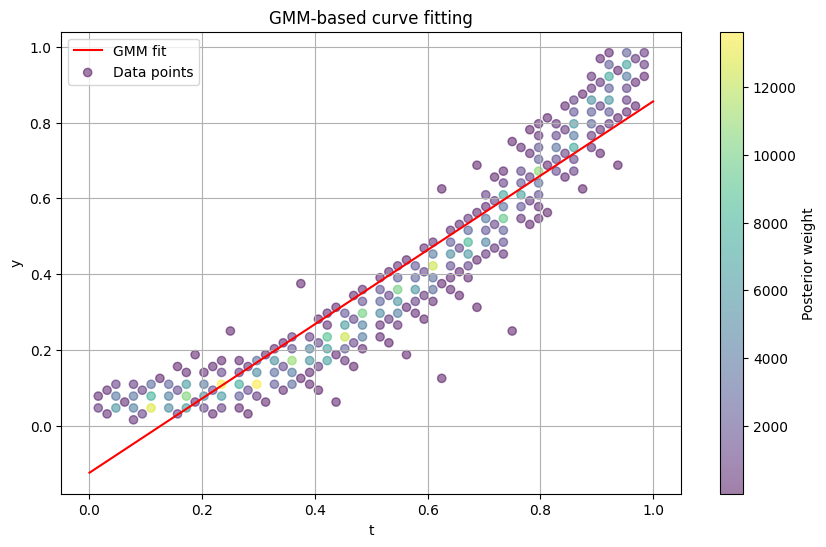

In [79]:
from sklearn.mixture import GaussianMixture  
import numpy as np  
  
def extract_high_posterior_curve_gmm(points_for_kde, n_components=3):    
    """Extract a curve using Gaussian Mixture Model instead of spline"""    
    # Prepare data for GMM: use only x,y coordinates  
    X = points_for_kde[:, :2]    
    weights = points_for_kde[:, 2]  # posterior values  
      
    # Normalize weights to probabilities  
    weights = weights / np.sum(weights)  
      
    # Resample points according to weights  
    n_samples = len(X)  
    resampled_indices = np.random.choice(n_samples, size=n_samples, p=weights)  
    X_resampled = X[resampled_indices]  
      
    # Fit GMM on resampled data  
    gmm = GaussianMixture(n_components=n_components, random_state=42)  
    gmm.fit(X_resampled)  
        
    # Create prediction function (similar interface to UnivariateSpline)    
    def gmm_predict(t):    
        t = np.atleast_1d(t)    
            
        y_pred = np.zeros_like(t, dtype=float)    
        for i, t_val in enumerate(t):    
            weighted_mean = 0.0    
            weight_sum = 0.0    
                
            for j in range(n_components):    
                mu_t, mu_y = gmm.means_[j]    
                sigma = gmm.covariances_[j]    
                sigma_tt = sigma[0, 0]    
                sigma_ty = sigma[0, 1]    
                    
                if sigma_tt < 1e-6:    
                    cond_mean = mu_y    
                else:    
                    cond_mean = mu_y + sigma_ty / sigma_tt * (t_val - mu_t)    
                    
                diff = t_val - mu_t    
                likelihood = np.exp(-0.5 * diff**2 / sigma_tt) / np.sqrt(2 * np.pi * sigma_tt)    
                    
                w = gmm.weights_[j] * likelihood    
                weighted_mean += w * cond_mean    
                weight_sum += w    
                
            y_pred[i] = weighted_mean / weight_sum if weight_sum > 0 else 0.0    
            
        return y_pred    
        
    return gmm_predict  
  
# Create an instance of PolyaTree  
#tree_ext = PolyaTree(alpha0=1.0, lam=0.5, beta=0.5, gamma=0.5, eta=0.5, max_depth=5)  
  
# Get posteriors  
#posterior_values, rectangles, points_for_kde = compute_tree_posteriors(tree_ext)  
  
# Extract curve using GMM  
curve_fit = extract_high_posterior_curve_gmm(points_for_kde, n_components=1)  
  
# Test the fit  
t_test = np.linspace(0, 1, 100)  
y_test = curve_fit(t_test)  
  
# Plot  
plt.figure(figsize=(10, 6))  
plt.plot(t_test, y_test, 'r-', label='GMM fit')  
plt.scatter(points_for_kde[:, 0], points_for_kde[:, 1], c=points_for_kde[:, 2],   
           cmap='viridis', alpha=0.5, label='Data points')  
plt.colorbar(label='Posterior weight')  
plt.xlabel('t')  
plt.ylabel('y')  
plt.title('GMM-based curve fitting')  
plt.legend()  
plt.grid(True)  
plt.show()  

In [37]:
data = np.empty((y_sample.shape[0], 2))
print(data.shape)
data[:,0], data[:,1] = t_sample, y_sample
np.savetxt("y.txt", data, fmt='%.18e', delimiter=' ')

(100, 2)


In [38]:
import aifeynman
aifeynman.run_aifeynman("./", "y.txt", 30,
              "14ops.txt", polyfit_deg=3, NN_epochs=500)

Checking for brute force + 

Trying to solve mysteries with brute force...
Trying to solve ./y.txt_train
Checking for brute force * 

Trying to solve mysteries with brute force...
Trying to solve ./y.txt_train
Checking polyfit 

Pareto frontier in the current branch:

Complexity #  MDL Loss #  Expression
68.35 25.39 -2.52*x0**3 + 1.87*x0**2 + 3.91*x0 - 3.38

Checking for brute force + 

Trying to solve mysteries with brute force...
Trying to solve results/mystery_world_squared/y.txt_train
Checking for brute force * 

Trying to solve mysteries with brute force...
Trying to solve results/mystery_world_squared/y.txt_train
Checking polyfit 

Pareto frontier in the current branch:

Complexity #  MDL Loss #  Expression
68.35 25.39 -2.52*x0**3 + 1.87*x0**2 + 3.91*x0 - 3.38

Checking for brute force + 

Trying to solve mysteries with brute force...
Trying to solve results/mystery_world_atan/y.txt_train
Checking for brute force * 

Trying to solve mysteries with brute force...
Trying to solve r

In [40]:
y_ai= np.arctan(-0.007756398966+np.cos((t_sample-np.sin(np.pi))))

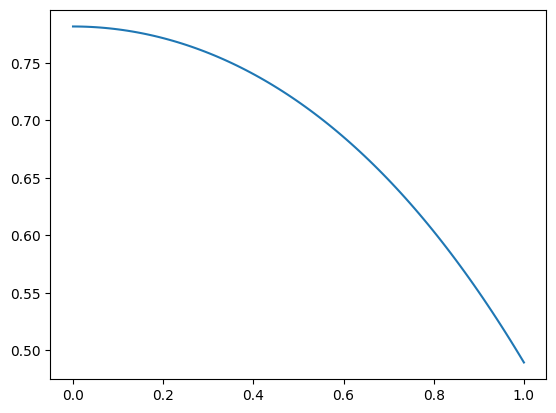

In [41]:
plt.plot(t_sample, y_ai)
plt.show()

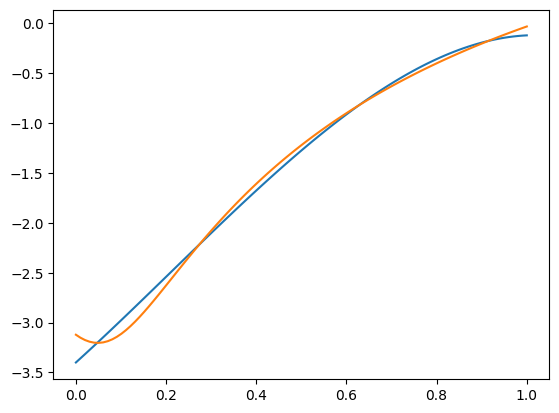

In [45]:
plt.plot(t_sample, -2.24*t_sample**3 + 1.42*t_sample**2 + 4.1*t_sample - 3.4)
plt.plot(t_sample, y_sample)
plt.show()

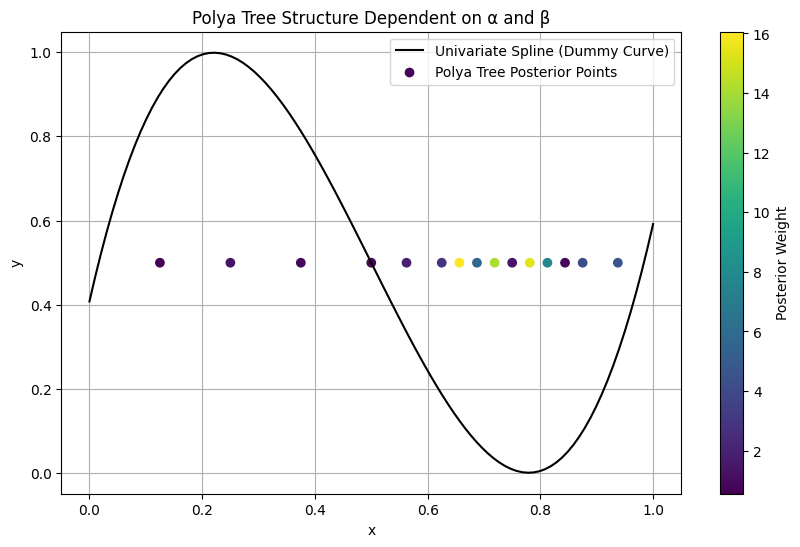

Posterior values: [ 0.79395977  1.28512006  0.55417563  0.79242247  1.45999335  2.8138515
  1.90574914  5.72307087 16.05665615 14.13061211  4.14323226  7.75564022
 15.41069957  0.81873283  4.61672075]
Rectangles: [(0.0, 0.0, 1.0, 1.0, 0.7939597682362691), (0.0, 0.0, 0.5, 1.0, 1.285120063829881), (0.0, 0.0, 0.25, 1.0, 0.554175627361215), (0.25, 0.0, 0.25, 1.0, 0.7924224681512755), (0.5, 0.0, 0.5, 1.0, 1.459993347634295), (0.5, 0.0, 0.25, 1.0, 2.813851497837595), (0.5, 0.0, 0.125, 1.0, 1.9057491355327527), (0.625, 0.0, 0.125, 1.0, 5.723070869606021), (0.625, 0.0, 0.0625, 1.0, 16.056656152034098), (0.6875, 0.0, 0.0625, 1.0, 14.130612107176537), (0.75, 0.0, 0.25, 1.0, 4.143232264603898), (0.75, 0.0, 0.125, 1.0, 7.755640215495606), (0.75, 0.0, 0.0625, 1.0, 15.410699565691269), (0.8125, 0.0, 0.0625, 1.0, 0.8187328347955984), (0.875, 0.0, 0.125, 1.0, 4.616720754441346)]
Points for KDE (head): [[0.5        0.5        0.79395977]
 [0.25       0.5        1.28512006]
 [0.125      0.5        0.554

In [98]:
# Now let's define the sympy conversion function
import sympy as sp
def model_to_sympy(model, poly, model_name="Model"):
    # Get feature names
    feature_names = poly.get_feature_names_out(['t'])
    
    # Get coefficients and intercept
    intercept = model.intercept_
    coefs = model.coef_
    
    # Create symbolic variable
    t_sym = sp.symbols('t')
    
    # Build expression starting with intercept
    expr = sp.nsimplify(intercept)
    
    # Start from index 1 since index 0 is the bias term (constant)
    for i in range(1, len(feature_names)):
        name = feature_names[i]
        if name == 't':
            power = 1
        elif '^' in name:
            power = int(name.split('^')[1])
        else:
            power = 0
            
        coef_val = coefs[i]
        if abs(coef_val) > 1e-10:  # Only include non-zero terms
            expr += sp.nsimplify(coef_val) * t_sym**power
    
    # Simplify and print
    expr = sp.simplify(expr)
    print(f"\
{model_name} equation:")
    sp.pretty_print(expr)
    return expr

# Convert each model to symbolic expression
print("Converting models to symbolic expressions...")
lasso_expr = model_to_sympy(lasso, poly, model_name="Lasso")
ridge_expr = model_to_sympy(ridge, poly, model_name="Ridge")
omp_expr = model_to_sympy(omp, poly, model_name="OMP")

Converting models to symbolic expressions...
Lasso equation:
 883688680982049  
──────────────────
100000000000000000
Ridge equation:
                 5                    4                   3                    ↪
  9694592251357⋅t    101256522451857⋅t    21072604705303⋅t    384786883123329⋅ ↪
- ──────────────── - ────────────────── - ───────────────── + ──────────────── ↪
  6250000000000000   50000000000000000    20000000000000000   1000000000000000 ↪

↪  2                                        
↪ t    21583066090877⋅t     36111091169487  
↪ ── + ──────────────── - ──────────────────
↪ 00   1250000000000000   250000000000000000
OMP equation:
                  5                   4                    3                   ↪
  50621930053437⋅t    20951025567833⋅t    247688888752991⋅t    218704619153067 ↪
- ───────────────── + ───────────────── - ────────────────── - ─────────────── ↪
  12500000000000000   2000000000000000    25000000000000000    100000000000000 ↪

↪   2                 

Lasso function at t = 0.5: 0.00883688680982049
Ridge function at t = 0.5: 0.009144001885751424
OMP function at t = 0.5: 0.009376197689411335


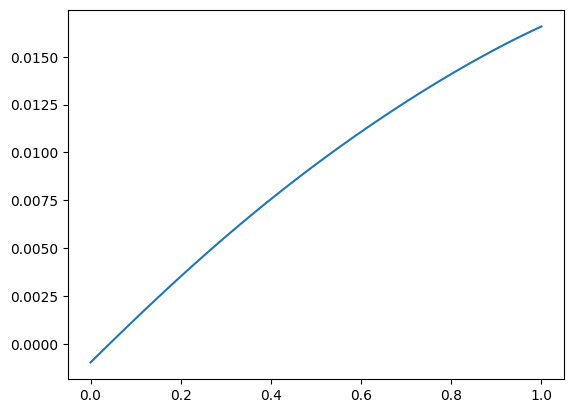

In [99]:
t_sym = sp.symbols('t')

# Lambdify the symbolic expressions into functions that take a numerical input for t
lasso_func = sp.lambdify(t_sym, lasso_expr, 'numpy')
ridge_func = sp.lambdify(t_sym, ridge_expr, 'numpy')
omp_func   = sp.lambdify(t_sym, omp_expr, 'numpy')

# Test the lambdified functions for a value, say t = 0.5
print("Lasso function at t = 0.5:", lasso_func(0.5))
print("Ridge function at t = 0.5:", ridge_func(0.5))
print("OMP function at t = 0.5:", omp_func(0.5))

plt.plot(t_sample, omp_func(t_sample))
plt.show()